In [ ]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 35.4 MB/s  0:00:00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT_DIR = '/content/drive/MyDrive/Lab_7_Checkpoints'
os.makedirs(PROJECT_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, re, time, json, random
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt
from numpy.linalg import norm
from scipy.stats import spearmanr

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

from datasets import load_dataset
import gensim.downloader as api
from gensim.test.utils import datapath

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
from sklearn.manifold import TSNE

from tqdm.auto import tqdm
import glob, pickle

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [ ]:
def _tam(path):
    try:
        return os.path.getsize(path)
    except OSError:
        return 0

def save_pickle(obj, nombre):
    path = os.path.join(PROJECT_DIR, nombre)
    tmp  = path + ".tmp"
    try:
        with open(tmp, "wb") as f:
            pickle.dump(obj, f, protocol=pickle.HIGHEST_PROTOCOL)
            f.flush()
            os.fsync(f.fileno())
        os.replace(tmp, path)
        print(f"  [pickle] guardado: {path}  ({_tam(path)/1e6:.1f} MB)")
    except Exception as e:
        print(f"  [pickle] ERROR guardando {nombre}: {e}")
        if os.path.exists(tmp):
            os.remove(tmp)
        raise

def load_pickle(nombre, min_bytes=16):
    path = os.path.join(PROJECT_DIR, nombre)
    if not os.path.exists(path):
        return None
    size = _tam(path)
    if size < min_bytes:
        print(f"  [pickle] {path} está vacío ({size} B) → se ignora y se borra.")
        try: os.remove(path)
        except OSError: pass
        return None
    try:
        with open(path, "rb") as f:
            obj = pickle.load(f)
        print(f"  [pickle] cargado: {path}  ({size/1e6:.1f} MB)")
        return obj
    except (EOFError, pickle.UnpicklingError, ValueError) as e:
        print(f"  [pickle] {path} corrupto ({e}) → se ignora y se borra.")
        try: os.remove(path)
        except OSError: pass
        return None

def save_checkpoint(model, optimizer, epoch, loss, nombre):
    ckpt = {
        'epoch': epoch,
        'model_state_dict': model.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': loss,
    }
    path = os.path.join(PROJECT_DIR, nombre)
    tmp  = path + ".tmp"
    torch.save(ckpt, tmp)
    os.replace(tmp, path)
    print(f"  [ckpt] guardado: {path}")

def last_checkpoint(patron):
    files = sorted(glob.glob(os.path.join(PROJECT_DIR, patron)))
    return files[-1] if files else None

In [ ]:
#cargandop datos
corpus = load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1")
news = load_dataset("fancyzhx/ag_news")
glove = api.load("glove-wiki-gigaword-100")
print("\nDatos listos...")

#benchmarks
analogias_path = datapath("questions-words.txt")
wordsim_path   = datapath("wordsim353.tsv")
simlex_path    = datapath("simlex999.txt")
print("Benchmarks listos...\n")
print(corpus)
print(news)
print(f"GloVe vocab: {len(glove.index_to_key)}  dim={glove.vector_size}")

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-103-raw-v1/test-00000-of-00001.(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-103-raw-v1/test-00000-of-00001.(…): downloading bytes:           |  0.00B            

wikitext-103-raw-v1/train-00000-of-00002(…): reconstructing file:   0%|          |  0.00B /  157MB            

wikitext-103-raw-v1/train-00000-of-00002(…): downloading bytes:           |  0.00B            

wikitext-103-raw-v1/train-00001-of-00002(…): reconstructing file:   0%|          |  0.00B /  157MB            

... (10 outputs left out)

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

[==================================================] 100.0% 128.1/128.1MB downloaded

Datos listos...
Benchmarks listos...

DatasetDict({
    test: Dataset({
        features: ['text'],
        num_rows: 4358
    })
    train: Dataset({
        features: ['text'],
        num_rows: 1801350
    })
    validation: Dataset({
        features: ['text'],
        num_rows: 3760
    })
})
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})
GloVe vocab: 400000  dim=100


=== TOKENIZACION ===
  [pickle] cargado: /content/drive/MyDrive/Lab_7_Checkpoints/tokens.pkl  (653.8 MB)
  [pickle] cargado: /content/drive/MyDrive/Lab_7_Checkpoints/freq.pkl  (6.2 MB)
Tokens cargados: 83,611,021
freq cargado: 476,946 tipos
Articulos: 1,801,350
Lineas: 2,966,379
Tokens: 83611021
=== FRECUENCIA Y LEY DE ZIPF ===


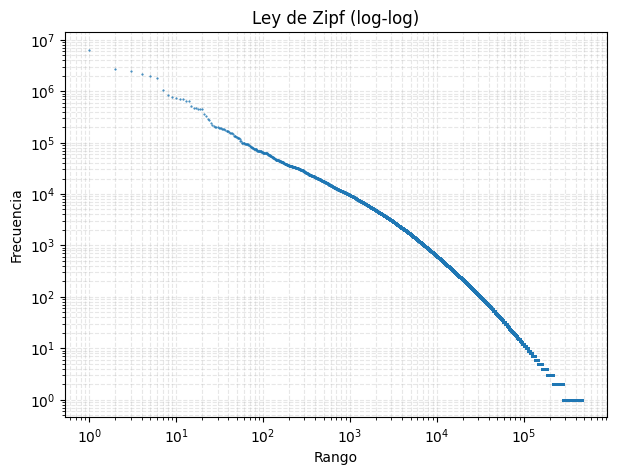

Top     10 cubren 25.21% de los tokens
Top   1000 cubren 65.68% de los tokens
Top  30000 cubren 95.76% de los tokens


In [ ]:
print("=== TOKENIZACION ===")
def tokenizar(texto):
    texto = texto.lower()
    return re.findall(r"[a-záéíóúñü]+(?:'[a-z]+)?", texto)

tokens = load_pickle("tokens.pkl")
freq   = load_pickle("freq.pkl")

train_text  = corpus["train"]["text"]
n_articulos = len(train_text)
n_lineas    = sum(t.count("\n") + 1 for t in train_text)

if tokens is None:
    tokens = []
    for t in tqdm(train_text, desc="Tokenizando"):
        tokens.extend(tokenizar(t))
    save_pickle(tokens, "tokens.pkl")
else:
    print(f"Tokens cargados: {len(tokens):,}")

if freq is None:
    freq = Counter(tokens)
    save_pickle(freq, "freq.pkl")
else:
    print(f"freq cargado: {len(freq):,} tipos")

print(f"Articulos: {n_articulos:,}")
print(f"Lineas: {n_lineas:,}")
print(f"Tokens: {len(tokens)}")

print("=== FRECUENCIA Y LEY DE ZIPF ===")
total = sum(freq.values())
ordenados = freq.most_common()
ranks     = np.arange(1, len(ordenados) + 1)
frecs     = np.array([c for _, c in ordenados], dtype=np.float64)

plt.figure(figsize=(7,5))
plt.loglog(ranks, frecs, '.', markersize=1)
plt.xlabel("Rango"); plt.ylabel("Frecuencia")
plt.title("Ley de Zipf (log-log)")
plt.grid(True, which="both", ls="--", alpha=0.3)
plt.show()

for k in [10, 1000, 30000]:
    cob = frecs[:k].sum() / total
    print(f"Top {k:>6} cubren {cob*100:.2f}% de los tokens")

In [ ]:
print("=== VOCABULARIO ===")

for mc in [1, 5, 10, 50]:
    v = {w: c for w, c in freq.items() if c >= mc}
    oov = sum(c for w, c in freq.items() if c < mc) / total
    print(f"min_count={mc:>3}  |V|={len(v):>8}  OOV={oov*100:6.2f}%")

MIN_COUNT = 5
vocab = load_pickle("vocab.pkl")
idx2word = load_pickle("idx2word.pkl")

if vocab is None or idx2word is None:
    palabras_vocab = [w for w, c in freq.items() if c >= MIN_COUNT]
    vocab = {"<unk>": 0, "<pad>": 1}
    for w in sorted(palabras_vocab, key=lambda x: -freq[x]):
        if w not in vocab:
            vocab[w] = len(vocab)
    idx2word = {i: w for w, i in vocab.items()}
    save_pickle(vocab, "vocab.pkl")
    save_pickle(idx2word, "idx2word.pkl")

print(f"|V| final = {len(vocab):,}")

print("--- submuestreo ---")
def prob_descarte(f, total, t=1e-5):
    f_norm = f/total
    return 1 - np.sqrt(t/f_norm)

for w in ["the", "of", "and"]:
    p = prob_descarte(freq[w], total)
    print(f"'{w}': freq={freq[w]:,}  P(desc)={p:.3f}  descartados≈{p*freq[w]:,.0f}")

def subsample(tokens, freq, total, t=1e-5):
    out = []
    probs = {}
    for w in tokens:
        if w not in probs:
            probs[w] = prob_descarte(freq[w], total, t)
        if np.random.rand() > probs[w]:
            out.append(w)
    return out

tokens_sub    = load_pickle("tokens_sub.pkl")
pares_con_sub = load_pickle("pares_con_sub.pkl")

if tokens_sub is None:
    tokens_sub = subsample(tokens, freq, total)
    save_pickle(tokens_sub, "tokens_sub.pkl")
    print(f"Tokens antes: {len(tokens):,}")
    print(f"Tokens despues: {len(tokens_sub):,}")
else:
    print(f"tokens_sub cargado: {len(tokens_sub):,}")

print("--- pares ---")
def generar_pares(tokens, vocab, ventana=5):
    ids = [vocab.get(w, vocab["<unk>"]) for w in tokens]
    pares = []
    for i, c in enumerate(ids):
        ini = max(0, i - ventana)
        fin = min(len(ids), i + ventana + 1)
        for j in range(ini, fin):
            if j != i:
                pares.append((c, ids[j]))
    return pares

VENTANA = 5
if pares_con_sub is None:
    pares_sin_sub = generar_pares(tokens[:200_000], vocab, VENTANA)
    pares_con_sub = generar_pares(tokens_sub[:200_000], vocab, VENTANA)
    save_pickle(pares_con_sub, "pares_con_sub.pkl")
    print(f"Pares sin submuestreo: {len(pares_sin_sub):,}")
else:
    print(f"pares_con_sub cargado: {len(pares_con_sub)}")

=== VOCABULARIO ===
min_count=  1  |V|=  476946  OOV=  0.00%
min_count=  5  |V|=  163118  OOV=  0.62%
min_count= 10  |V|=  111800  OOV=  1.02%
min_count= 50  |V|=   47336  OOV=  2.70%
  [pickle] cargado: /content/drive/MyDrive/Lab_7_Checkpoints/vocab.pkl  (2.4 MB)
  [pickle] cargado: /content/drive/MyDrive/Lab_7_Checkpoints/idx2word.pkl  (2.4 MB)
|V| final = 163,120
--- submuestreo ---
'the': freq=6,439,060  P(desc)=0.989  descartados≈6,365,686
'of': freq=2,743,116  P(desc)=0.983  descartados≈2,695,225
'and': freq=2,505,793  P(desc)=0.982  descartados≈2,460,021
  [pickle] cargado: /content/drive/MyDrive/Lab_7_Checkpoints/tokens_sub.pkl  (243.6 MB)
  [pickle] cargado: /content/drive/MyDrive/Lab_7_Checkpoints/pares_con_sub.pkl  (15.9 MB)
tokens_sub cargado: 25,003,230
--- pares ---
pares_con_sub cargado: 1999970


In [ ]:
print("=== DATASET Y DATALOADERS ===")

def unigram_075(freq, vocab):
    counts = np.array([freq.get(w, 0) for w in vocab], dtype=np.float64)
    counts[vocab["<unk>"]] = 0
    p = counts ** 0.75
    return p/p.sum()

p_neg = unigram_075(freq, vocab)

class SkipGramDataset(Dataset):
    def __init__(self, pares, p_neg, K=5):
        self.pares = pares
        self.p_neg = p_neg
        self.K = K
    def __len__(self):
        return len(self.pares)
    def __getitem__(self, i):
        c, ctx = self.pares[i]
        negs = np.random.choice(len(self.p_neg), size=self.K, p=self.p_neg)
        return c, ctx, negs

ds = SkipGramDataset(pares_con_sub, p_neg, K=5)
dl = DataLoader(ds, batch_size=4096, shuffle=True, num_workers=0)
print(f"Batches por epoch: {len(dl):,}")

=== DATASET Y DATALOADERS ===
Batches por epoch: 489


In [ ]:
print("=== SGNS ===")

class SGNS(nn.Module):
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.in_emb  = nn.Embedding(vocab_size, dim)
        self.out_emb = nn.Embedding(vocab_size, dim)
        init = 0.5 / dim
        nn.init.uniform_(self.in_emb.weight, -init, init)
        nn.init.zeros_(self.out_emb.weight)

    def forward(self, center, context, negatives):
        v  = self.in_emb(center)#(B,d)
        u  = self.out_emb(context)#(B,d)
        un = self.out_emb(negatives)#(B,K,d)
        pos = torch.sum(v * u, dim=1)#(B,)
        neg = torch.bmm(un, v.unsqueeze(2)).squeeze(2)#(B,K)
        return -F.logsigmoid(pos).mean() - F.logsigmoid(-neg).mean()

DIM = 100
model = SGNS(len(vocab), DIM).to(device)
print(model)

=== SGNS ===
SGNS(
  (in_emb): Embedding(163120, 100)
  (out_emb): Embedding(163120, 100)
)


In [ ]:
print("=== ENTRENAMIENTO ===")

def entrenar(model, dl, epochs=5, lr=0.025, ckpt_patron="sgns_ckpt_epoch*.pt"):
    opt = optim.Adam(model.parameters(), lr=lr)
    historia = []
    start_epoch = 0
    ckpt_prev = last_checkpoint(ckpt_patron)
    if ckpt_prev is not None:
        ck = torch.load(ckpt_prev, map_location=device)
        model.load_state_dict(ck['model_state_dict'])
        opt.load_state_dict(ck['optimizer_state_dict'])
        start_epoch = ck['epoch'] + 1
        print(f"Usando {ckpt_prev} (epoch {start_epoch})")

    for ep in range(start_epoch, epochs):
        t0 = time.time(); tot_loss = 0; n = 0
        model.train()
        for c, ctx, neg in tqdm(dl, desc=f"Epoch {ep+1}"):
            c, ctx, neg = c.to(device), ctx.to(device), neg.to(device)
            opt.zero_grad()
            loss = model(c, ctx, neg)
            loss.backward(); opt.step()
            tot_loss += loss.item(); n += 1
        prom = tot_loss / n
        historia.append(prom)
        print(f"Epoch {ep+1}: loss={prom:.4f}  tiempo={time.time()-t0:.1f}s")
        save_checkpoint(model, opt, ep, prom, f"sgns_ckpt_epoch{ep:02d}.pt")

    return historia

hist = entrenar(model, dl, epochs=5, lr=0.025)

def extraer_vectores(model, vocab):
    W = model.in_emb.weight.detach().cpu().numpy()
    return {w: W[i] for w, i in vocab.items()}

vecs_sgns = load_pickle("vecs_sgns.pkl")
if vecs_sgns is None:
    vecs_sgns = extraer_vectores(model, vocab)
    save_pickle(vecs_sgns, "vecs_sgns.pkl")

print(f"Vocab SGNS: {len(vecs_sgns):,}")
print(f"Dim:  {next(iter(vecs_sgns.values())).shape}")
print(f"'king' in vocab: {'king' in vecs_sgns}")

vecs_glove = load_pickle("vecs_glove.pkl")
if vecs_glove is None:
    vecs_glove = {w.lower(): glove[w] for w in glove.index_to_key if w.isalpha()}
    save_pickle(vecs_glove, "vecs_glove.pkl")

print(f"Vocab GloVe: {len(vecs_glove):,}")
print(f"'king' in vocab: {'king' in vecs_glove}")

=== ENTRENAMIENTO ===


Epoch 1:   0%|          | 0/489 [00:00<?, ?it/s]

Epoch 1: loss=1.1606  tiempo=4575.7s
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/sgns_ckpt_epoch00.pt


Epoch 2:   0%|          | 0/489 [00:00<?, ?it/s]

Epoch 2: loss=0.8365  tiempo=4510.4s
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/sgns_ckpt_epoch01.pt


Epoch 3:   0%|          | 0/489 [00:00<?, ?it/s]

Epoch 3: loss=0.7399  tiempo=4418.8s
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/sgns_ckpt_epoch02.pt


Epoch 4:   0%|          | 0/489 [00:00<?, ?it/s]

Epoch 4: loss=0.7123  tiempo=4460.3s
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/sgns_ckpt_epoch03.pt


Epoch 5:   0%|          | 0/489 [00:00<?, ?it/s]

Epoch 5: loss=0.7028  tiempo=4468.7s
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/sgns_ckpt_epoch04.pt
  [pickle] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/vecs_sgns.pkl  (71.1 MB)
Vocab SGNS: 163,120
Dim:  (100,)
'king' in vocab: True
  [pickle] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/vecs_glove.pkl  (141.1 MB)
Vocab GloVe: 327,091
'king' in vocab: True


In [ ]:
print("=== SIMILITUD Y ANALOGIAS ===")

def sim_cos(v1, v2):
    return float(np.dot(v1, v2)/(norm(v1)*norm(v2) + 1e-12))

def normalizar_matriz(M):
    return M / (norm(M, axis=1, keepdims=True)+1e-12)

def analogia_3cosadd(vecs, a, b, c, k=5, excluir=True):
    if any(w not in vecs for w in (a, b, c)):
        faltan = [w for w in (a, b, c) if w not in vecs]
        print(f" - Faltan: {faltan}")
        return []
    target = vecs[b] - vecs[a] + vecs[c]
    palabras = list(vecs.keys())
    M = normalizar_matriz(np.stack([vecs[w] for w in palabras]))
    t = target / (norm(target)+1e-12)
    sims = M @ t
    idx = np.argsort(-sims)
    excl = {a, b, c} if excluir else set()
    out = []
    for i in idx:
        w = palabras[i]
        if w in excl:
            continue
        out.append((w, float(sims[i])))
        if len(out) == k:
            break
    return out

def analogia_3cosmul(vecs, a, b, c, k=5):
    if any(w not in vecs for w in (a, b, c)):
        return []
    va = np.array(vecs[a], dtype=np.float64, copy=True)
    vb = np.array(vecs[b], dtype=np.float64, copy=True)
    vc = np.array(vecs[c], dtype=np.float64, copy=True)
    va /= (norm(va) + 1e-12)
    vb /= (norm(vb) + 1e-12)
    vc /= (norm(vc) + 1e-12)
    palabras = list(vecs.keys())
    M = normalizar_matriz(np.stack([vecs[w] for w in palabras]))
    sims = (1 + M @ vb) * (1 + M @ vc) / ((1 + M @ va) + 1e-12)
    idx = np.argsort(-sims)
    excl = {a, b, c}
    out = []
    for i in idx:
        w = palabras[i]
        if w in excl: continue
        out.append((w, float(sims[i])))
        if len(out) == k: break
    return out

print("--- ejemplo ---")
VECS = vecs_glove
a, b, c = "man", "woman", "king"

print(f"{a} : {b} :: {c} : ?")
for w, s in analogia_3cosadd(VECS, a, b, c, k=5):
    print(f"   {w:15s} {s:.3f}")

=== SIMILITUD Y ANALOGIAS ===
--- ejemplo ---
man : woman :: king : ?
   queen           0.783
   monarch         0.693
   throne          0.683
   daughter        0.681
   prince          0.671


In [ ]:
print("=== ANALOGIAS ===")

analogias_propias = [
    #genero
    ("man", "woman", "king"),
    ("actor", "actress", "prince"),
    #pais-capital
    ("france", "paris", "italy"),
    ("japan", "tokyo", "germany"),
    ("spain", "madrid", "portugal"),
    #pais-gentilicio
    ("spain", "spanish", "france"),
    ("japan", "japanese", "china"),
    #comparativos/superlativos
    ("good", "better", "bad"),
    ("big", "bigger", "small"),
    ("hot", "hotter", "cold"),
    #tiempos
    ("go", "went", "eat"),
    ("run", "ran", "swim"),
    ("take", "took", "give"),
    #plurales
    ("cat", "cats", "dog"),
    ("child", "children", "man"),
]

for a, b, c in analogias_propias:
    print(f"\n{a} : {b} :: {c} : ?")
    for w, s in analogia_3cosadd(VECS, a, b, c, k=5):
        print(f"   {w:15s} {s:.3f}")

def cargar_tsv(path):
    with open(path, encoding="utf-8") as f:
        for line in f:
            p = line.strip().split("\t")
            if len(p) < 3:
                continue
            try:
                score = float(p[2])
            except ValueError:
                continue
            yield p[0].lower(), p[1].lower(), score

def evaluar_similitud(vecs, path):
    gold, pred = [], []
    for w1, w2, s in cargar_tsv(path):
        if w1 in vecs and w2 in vecs:
            gold.append(s); pred.append(sim_cos(vecs[w1], vecs[w2]))
    rho, _ = spearmanr(gold, pred)
    print(f"Spearman: {rho:.4f}  (n={len(gold)})")
    return rho

def guardar_word2vec_txt(vecs, path):
    dim = len(next(iter(vecs.values())))
    with open(path, "w", encoding="utf-8") as f:
        f.write(f"{len(vecs)} {dim}\n")
        for w, v in vecs.items():
            f.write(w + " " + " ".join(f"{x:.6f}" for x in v) + "\n")

=== ANALOGIAS ===

man : woman :: king : ?
   queen           0.783
   monarch         0.693
   throne          0.683
   daughter        0.681
   prince          0.671

actor : actress :: prince : ?
   princess        0.833
   queen           0.733
   daughter        0.693
   duchess         0.681
   niece           0.643

france : paris :: italy : ?
   rome            0.808
   milan           0.732
   naples          0.709
   venice          0.701
   turin           0.697

japan : tokyo :: germany : ?
   frankfurt       0.838
   berlin          0.816
   munich          0.732
   paris           0.709
   hamburg         0.696

spain : madrid :: portugal : ?
   lisbon          0.779
   porto           0.754
   barcelona       0.731
   benfica         0.725
   milan           0.677

spain : spanish :: france : ?
   french          0.932
   belgian         0.723
   dutch           0.706
   italian         0.702
   british         0.692

japan : japanese :: china : ?
   chinese         0.95

=== EVALUACION ===

=== GloVe - 3CosAdd ===
 M (precomp): (327091, 100)  (0.7s)
  - 2000 analogias  (24.4s)
  - 4000 analogias  (48.7s)
  - 6000 analogias  (72.6s)
  - 8000 analogias  (95.4s)
family                          80.63%  (408/506)
gram1-adjective-to-adverb       23.69%  (235/992)
gram2-opposite                  20.69%  (168/812)
gram3-comparative               80.26%  (1069/1332)
gram4-superlative               56.15%  (630/1122)
gram5-present-participle        69.13%  (730/1056)
gram7-past-tense                53.46%  (834/1560)
gram8-plural                    71.70%  (955/1332)
gram9-plural-verbs              58.39%  (508/870)
TOTAL                           57.79%  (5537/9582)
  Tiempo total: 113.2s

=== GloVe - 3CosMul ===
 M (precomp): (327091, 100)  (0.8s)
  - 2000 analogias  (73.0s)
  - 4000 analogias  (144.9s)
  - 6000 analogias  (217.1s)
  - 8000 analogias  (289.4s)
family                          78.06%  (395/506)
gram1-adjective-to-adverb       23.19%  (230/992)
g

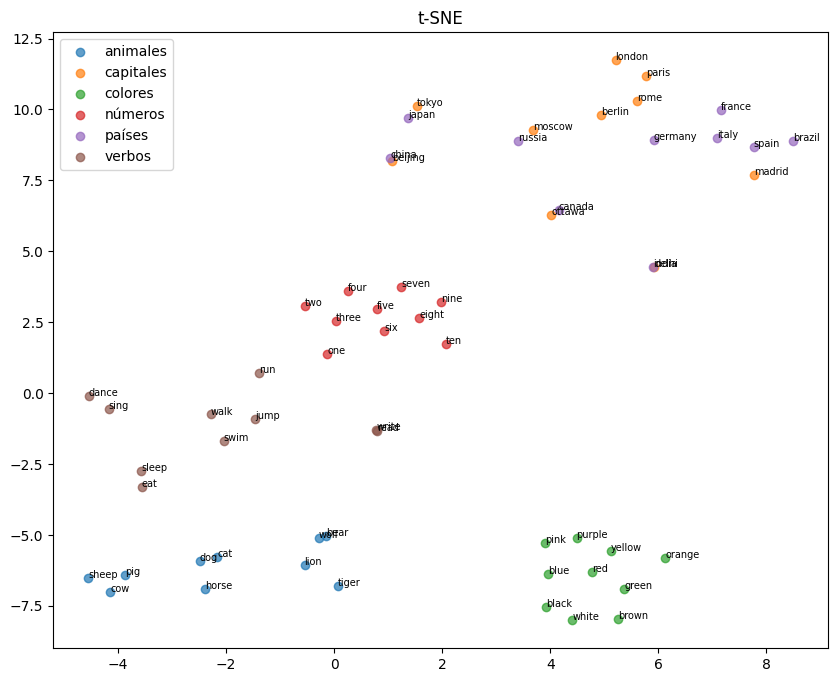

Guardado /content/drive/MyDrive/Lab_7_Checkpoints/sgns.txt y vectores/sgns.txt


In [ ]:
print("=== EVALUACION ===")

def eval_analogias(vecs, path, metodo="3cosadd", vocab_comun=None, verbose=True):
    t0 = time.time()
    palabras = list(vecs.keys())
    idx_de   = {w: i for i, w in enumerate(palabras)}

    M = np.stack([vecs[w] for w in palabras]).astype(np.float32, copy=False)
    M = M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-12)
    if verbose:
        print(f" M (precomp): {M.shape}  ({time.time()-t0:.1f}s)")

    def top1_add(a, b, c):
        t = (vecs[b] - vecs[a] + vecs[c]).astype(np.float32)
        t = t / (np.linalg.norm(t) + 1e-12)
        sims = M @ t
        for w in (a, b, c):
            i = idx_de.get(w)
            if i is not None: sims[i] = -np.inf
        return palabras[int(np.argmax(sims))]

    def top1_mul(a, b, c):
        va = np.array(vecs[a], dtype=np.float32, copy=True); va /= (np.linalg.norm(va)+1e-12)
        vb = np.array(vecs[b], dtype=np.float32, copy=True); vb /= (np.linalg.norm(vb)+1e-12)
        vc = np.array(vecs[c], dtype=np.float32, copy=True); vc /= (np.linalg.norm(vc)+1e-12)
        sims = (1 + M @ vb) * (1 + M @ vc) / ((1 + M @ va) + 1e-12)
        for w in (a, b, c):
            i = idx_de.get(w)
            if i is not None: sims[i] = -np.inf
        return palabras[int(np.argmax(sims))]

    acc = defaultdict(lambda: [0, 0])
    n = 0
    for cat, a, b, c, d in cargar_analogias(path):
        if vocab_comun and any(w not in vocab_comun for w in (a,b,c,d)): continue
        if any(w not in idx_de for w in (a,b,c,d)): continue
        pred = top1_add(a,b,c) if metodo=="3cosadd" else top1_mul(a,b,c)
        acc[cat][1] += 1
        if pred == d: acc[cat][0] += 1
        n += 1
        if verbose and n % 2000 == 0:
            print(f"  - {n} analogias  ({time.time()-t0:.1f}s)")

    tot_c = tot_t = 0
    for cat in sorted(acc):
        corr, tot = acc[cat]; tot_c += corr; tot_t += tot
        print(f"{cat:30s} {corr/tot*100:6.2f}%  ({corr}/{tot})")
    print(f"{'TOTAL':30s} {tot_c/tot_t*100:6.2f}%  ({tot_c}/{tot_t})")
    print(f"  Tiempo total: {time.time()-t0:.1f}s")
    return acc

print("\n=== GloVe - 3CosAdd ===")
acc_add = eval_analogias(vecs_glove, analogias_path, metodo="3cosadd")

print("\n=== GloVe - 3CosMul ===")
acc_mul = eval_analogias(vecs_glove, analogias_path, metodo="3cosmul")

print("\nWordSim-353 (GloVe):"); evaluar_similitud(vecs_glove, wordsim_path)
print("SimLex-999  (GloVe):"); evaluar_similitud(vecs_glove, simlex_path)

grupos = {
    "países":  ["france","germany","italy","spain","japan","china","brazil","canada","india","russia"],
    "números": ["one","two","three","four","five","six","seven","eight","nine","ten"],
    "animales":["dog","cat","horse","cow","pig","sheep","lion","tiger","bear","wolf"],
    "verbos":  ["run","eat","sleep","walk","jump","read","write","sing","dance","swim"],
    "colores": ["red","blue","green","yellow","black","white","pink","brown","orange","purple"],
    "capitales":["paris","london","rome","madrid","tokyo","beijing","berlin","moscow","ottawa","delhi"],
}

palabras, etiquetas = [], []
for g, ws in grupos.items():
    for w in ws:
        if w in VECS:
            palabras.append(w); etiquetas.append(g)

M = np.stack([VECS[w] for w in palabras])
Y = TSNE(n_components=2, perplexity=15, random_state=SEED).fit_transform(M)

plt.figure(figsize=(10,8))
for g in sorted(set(etiquetas)):
    idx = [i for i,e in enumerate(etiquetas) if e==g]
    plt.scatter(Y[idx,0], Y[idx,1], label=g, alpha=0.7)
    for i in idx:
        plt.annotate(palabras[i], (Y[i,0], Y[i,1]), fontsize=7)
plt.legend()
plt.title("t-SNE")
plt.show()

if vecs_sgns is not None:
    os.makedirs("vectores", exist_ok=True)
    guardar_word2vec_txt(vecs_sgns, os.path.join(PROJECT_DIR, "sgns.txt"))
    guardar_word2vec_txt(vecs_sgns, "vectores/sgns.txt")
    print(f"Guardado {os.path.join(PROJECT_DIR, 'sgns.txt')} y vectores/sgns.txt")
else:
    print("No hay sgns.txt")

In [ ]:
print("=== AG NEWS ===")

def preprocesar_ag(ex):
    return {"tokens": tokenizar(ex["text"])}

news_tok = news.map(preprocesar_ag)

X_tr_full = news_tok["train"]["tokens"]
y_tr_full = news_tok["train"]["label"]
X_test = news_tok["test"]["tokens"]
y_test = news_tok["test"]["label"]

X_tr, X_val, y_tr, y_val = train_test_split(
    X_tr_full, y_tr_full, test_size=0.10, stratify=y_tr_full, random_state=SEED
)
print(len(X_tr), len(X_val), len(X_test))

def oov_rate(tokens_list, vocab_model):
    tot = oov = 0
    for toks in tokens_list:
        for t in toks:
            tot += 1
            if t not in vocab_model:
                oov += 1
    return oov / max(tot, 1)

for nombre, v in [("SGNS", vecs_sgns), ("GloVe", vecs_glove)]:
    print(f"{nombre}: OOV train={oov_rate(X_tr, v)*100:.2f}%  "
          f"val={oov_rate(X_val, v)*100:.2f}%  "
          f"test={oov_rate(X_test, v)*100:.2f}%")

=== AG NEWS ===


Map:   0%|          | 0/120000 [00:00<?, ? examples/s]

Map:   0%|          | 0/7600 [00:00<?, ? examples/s]

108000 12000 7600
SGNS: OOV train=2.33%  val=2.31%  test=2.27%
GloVe: OOV train=1.10%  val=1.10%  test=1.06%


In [ ]:
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2), min_df=2)
Xtr_t = tfidf.fit_transform([" ".join(t) for t in X_tr])
Xva_t = tfidf.transform([" ".join(t) for t in X_val])
Xte_t = tfidf.transform([" ".join(t) for t in X_test])

clf = LogisticRegression(max_iter=200, n_jobs=-1)
clf.fit(Xtr_t, y_tr)
print(classification_report(y_val, clf.predict(Xva_t), digits=4))

class ClasificadorEmb(nn.Module):
    def __init__(self, emb_matrix, n_clases=4, freeze=False):
        super().__init__()
        V, d = emb_matrix.shape
        self.emb = nn.EmbeddingBag(V, d, mode="mean", padding_idx=0)
        with torch.no_grad():
            self.emb.weight.copy_(torch.tensor(emb_matrix, dtype=torch.float32))
        if freeze:
            self.emb.weight.requires_grad = False
        self.fc = nn.Linear(d, n_clases)

    def forward(self, ids, offsets):
        return self.fc(self.emb(ids, offsets))


def encode_batch(tokens_list, vocab_emb, max_len=64):
    ids, offsets = [], [0]
    for toks in tokens_list:
        seq = [vocab_emb.get(t, vocab_emb.get("<unk>", 0)) for t in toks[:max_len]] or [0]
        ids.extend(seq)
        offsets.append(offsets[-1] + len(seq))
    return (torch.tensor(ids, dtype=torch.long),
            torch.tensor(offsets[:-1], dtype=torch.long))

def construir_vocab_emb(vecs):
    return {w: i for i, w in enumerate(vecs.keys())}

def train_loader(X, y, vocab_emb, bs=128):
    for i in range(0, len(X), bs):
        yield encode_batch(X[i:i+bs], vocab_emb), torch.tensor(y[i:i+bs])

def entrenar_clas(model, vocab_emb, X_tr, y_tr, X_val, y_val,
                  epochs=5, lr=1e-3, nombre_ckpt="clas_ckpt"):
    model.to(device)
    opt = optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)
    crit = nn.CrossEntropyLoss()

    start_epoch = 0
    ckpt_prev = last_checkpoint(f"{nombre_ckpt}_epoch*.pt")
    if ckpt_prev is not None:
        ck = torch.load(ckpt_prev, map_location=device)
        model.load_state_dict(ck['model_state_dict'])
        opt.load_state_dict(ck['optimizer_state_dict'])
        start_epoch = ck['epoch'] + 1
        print(f"- {nombre_ckpt} desde epoch {start_epoch}")

    for ep in range(start_epoch, epochs):
        model.train()
        for (ids, off), yb in train_loader(X_tr, y_tr, vocab_emb):
            ids, off, yb = ids.to(device), off.to(device), yb.to(device)
            opt.zero_grad()
            loss = crit(model(ids, off), yb)
            loss.backward(); opt.step()

        model.eval(); correct = tot = 0
        with torch.no_grad():
            for (ids, off), yb in train_loader(X_val, y_val, vocab_emb, bs=256):
                ids, off, yb = ids.to(device), off.to(device), yb.to(device)
                pred = model(ids, off).argmax(1)
                correct += (pred == yb).sum().item(); tot += yb.size(0)
        val_acc = correct/tot
        print(f"Ep {ep+1}: val_acc={val_acc:.4f}")
        save_checkpoint(model, opt, ep, val_acc, f"{nombre_ckpt}_epoch{ep:02d}.pt")

              precision    recall  f1-score   support

           0     0.9336    0.9090    0.9211      3000
           1     0.9534    0.9827    0.9678      3000
           2     0.9007    0.8923    0.8965      3000
           3     0.9058    0.9103    0.9081      3000

    accuracy                         0.9236     12000
   macro avg     0.9234    0.9236    0.9234     12000
weighted avg     0.9234    0.9236    0.9234     12000



In [ ]:
print("=== ENTRENAMIENTO SGNS/GLOVE ===")

for nombre, vecs in [("SGNS", vecs_sgns), ("GloVe", vecs_glove)]:
    vocab_emb = construir_vocab_emb(vecs)
    M = np.stack([vecs[w] for w in vocab_emb])
    for freeze in [True, False]:
        print(f"\n--- {nombre} freeze={freeze} ---")
        m = ClasificadorEmb(M, n_clases=4, freeze=freeze)
        entrenar_clas(
            m, vocab_emb, X_tr, y_tr, X_val, y_val,
            epochs=3, lr=1e-3,
            nombre_ckpt=f"clas_{nombre}_freeze{int(freeze)}"
        )

=== ENTRENAMIENTO SGNS/GLOVE ===

--- SGNS freeze=True ---
Ep 1: val_acc=0.7572
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/clas_SGNS_freeze1_epoch00.pt
Ep 2: val_acc=0.7655
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/clas_SGNS_freeze1_epoch01.pt
Ep 3: val_acc=0.7722
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/clas_SGNS_freeze1_epoch02.pt

--- SGNS freeze=False ---
Ep 1: val_acc=0.8966
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/clas_SGNS_freeze0_epoch00.pt
Ep 2: val_acc=0.9134
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/clas_SGNS_freeze0_epoch01.pt
Ep 3: val_acc=0.9166
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/clas_SGNS_freeze0_epoch02.pt

--- GloVe freeze=True ---
Ep 1: val_acc=0.8694
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/clas_GloVe_freeze1_epoch00.pt
Ep 2: val_acc=0.8761
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/clas_GloVe_freeze1_epoch01.pt
Ep 3:

=== ENTRENAMIENTO (modelo final GloVe) ===
Ep 1: val_acc=0.9050
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/clas_final_glove_epoch00.pt
Ep 2: val_acc=0.9162
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/clas_final_glove_epoch01.pt
Ep 3: val_acc=0.9201
  [ckpt] guardado: /content/drive/MyDrive/Lab_7_Checkpoints/clas_final_glove_epoch02.pt
              precision    recall  f1-score   support

       World     0.9255    0.9095    0.9174      1900
      Sports     0.9578    0.9805    0.9691      1900
    Business     0.8939    0.8779    0.8858      1900
    Sci/Tech     0.8923    0.9026    0.8974      1900

    accuracy                         0.9176      7600
   macro avg     0.9174    0.9176    0.9174      7600
weighted avg     0.9174    0.9176    0.9174      7600



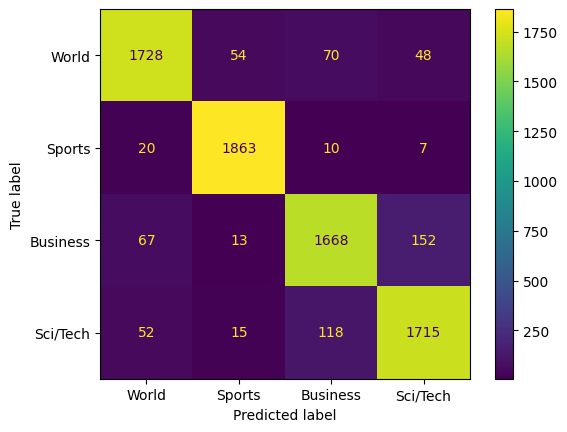

In [ ]:
print("=== ENTRENAMIENTO (modelo final GloVe) ===")

def evaluar_test(model, vocab_emb, X_test, y_test):
    model.eval(); preds = []
    with torch.no_grad():
        for (ids, off), _ in train_loader(X_test, y_test, vocab_emb, bs=256):
            ids, off = ids.to(device), off.to(device)
            preds.extend(model(ids, off).argmax(1).cpu().tolist())
    return np.array(preds)

vocab_emb = construir_vocab_emb(vecs_glove)
M = np.stack([vecs_glove[w] for w in vocab_emb])
modelo_final = ClasificadorEmb(M, n_clases=4, freeze=False)
entrenar_clas(
    modelo_final, vocab_emb, X_tr, y_tr, X_val, y_val,
    epochs=3, lr=1e-3,
    nombre_ckpt="clas_final_glove"
)

preds = evaluar_test(modelo_final, vocab_emb, X_test, y_test)
print(classification_report(y_test, preds,
      target_names=["World","Sports","Business","Sci/Tech"], digits=4))

cm = confusion_matrix(y_test, preds)
ConfusionMatrixDisplay(cm, display_labels=["World","Sports","Business","Sci/Tech"]).plot()
plt.show()

# Investigacion



- nn.Embedding: hace una tabla de embeddings indexable. Sus parametros son
  - num_embeddings: tamaño vocabulario
  - embedding_dim: dimesnion d
  - padding_idx: indice que siempre devuelve vector 0 por lo que no se actualiza
  - sparse: si es True usa gradiente disperso, haciendo que sea muy util con vocabularios enormes
- nn.Embedding.from_pretrained: Carga pesos preentrenados. freeze=True congela los embeddings mirnytsd que freeze=False permite fine-tuning.
- nn.EmbeddingBag: Evita que se materialize la sequencia entera al agregar embeddings de un "bag" de índices. Sus parametros son mode ('mean', 'sum', 'max') y offsets (indices donde empieza cada bolsa en un tensor plano)

- Conceptos:
  - CBOW vs Skip-gram: CBOW predice la palabra central a partir del contexto (es rapido y mejor para frecuencias altas). Skip-gram predice el contexto a partir del centro (mejor para palabras raras pero es lento).
  - Dos matrices W y W': W (input) aprende representaciones (y se conserva como el embedding final) y W' (output) es el clasificador sobre el vocabulario.
  - Word2Vec vs GloVe: Word2Vec es predictivo y GloVe esta basado en conteos globales de co-ocurrencia con factorizacion ponderada.

In [ ]:
#SGNS
class SGNS(nn.Module):
    def __init__(self, vocab_size, dim):
        super().__init__()
        self.in_emb  = nn.Embedding(vocab_size, dim)
        self.out_emb = nn.Embedding(vocab_size, dim)
        init = 0.5 / dim
        nn.init.uniform_(self.in_emb.weight, -init, init)
        nn.init.zeros_(self.out_emb.weight)

    def forward(self, center, context, negatives):
        #center:(B,) context:(B,) neg:(B,K)
        v  = self.in_emb(center) #(B,d)
        u  = self.out_emb(context) #(B,d)
        un = self.out_emb(negatives) #(B,K,d)

        pos = torch.sum(v * u, dim=1) #(B,)
        neg = torch.bmm(un, v.unsqueeze(2)).squeeze(2) #(B,K)

        pos_loss = -F.logsigmoid(pos).mean()
        neg_loss = -F.logsigmoid(-neg).mean()
        return pos_loss + neg_loss

In [ ]:
#Ddist negativos
def unigram_075(freq, vocab):
    counts = np.array([freq.get(w, 0) for w in vocab], dtype=np.float64)
    counts[vocab["<unk>"]] = 0
    p = counts ** 0.75
    p = p / p.sum()
    return p

p_neg = unigram_075(freq, vocab)

In [ ]:
#dataset y dataloaders
class SkipGramDataset(Dataset):
    def __init__(self, pares, K=5):
        self.pares = pares
        self.K = K
    def __len__(self):
        return len(self.pares)
    def __getitem__(self, i):
        c, ctx = self.pares[i]
        negs = np.random.choice(len(p_neg), size=self.K, p=p_neg)
        return c, ctx, negs

ds = SkipGramDataset(pares_con_sub, K=5)
dl = DataLoader(ds, batch_size=4096, shuffle=True, num_workers=2)

In [ ]:
#loop entrenameinto
def entrenar(model, dl, epochs=5, lr=0.025, device="cuda"):
    model.to(device)
    opt = optim.Adam(model.parameters(), lr=lr)
    historia = []
    for ep in range(epochs):
        t0 = time.time()
        total_loss = 0; n = 0
        for c, ctx, neg in tqdm(dl, desc=f"Epoch {ep+1}"):
            c, ctx, neg = c.to(device), ctx.to(device), neg.to(device)
            opt.zero_grad()
            loss = model(c, ctx, neg)
            loss.backward()
            opt.step()
            total_loss += loss.item(); n += 1
        prom = total_loss / n
        historia.append(prom)
        print(f"Epoch {ep+1}: loss={prom:.4f}  t={time.time()-t0:.1f}s")
    return historia

model = SGNS(vocab_size=len(vocab), dim=100)
hist = entrenar(model, dl, epochs=5, lr=0.025)

Epoch 1:   0%|          | 0/489 [00:00<?, ?it/s]

Epoch 1: loss=1.1610  t=2239.7s


Epoch 2:   0%|          | 0/489 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a00525f8720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a00525f8720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 2: loss=0.8381  t=2172.8s


Epoch 3:   0%|          | 0/489 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a00525f8720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7a00525f8720>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1706, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1675, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

In [ ]:
def extraer_vectores(model, vocab):
    W = model.in_emb.weight.detach().cpu().numpy()
    return {w: W[i] for w, i in vocab.items()}

In [ ]:
print("=== EVALUACION INTRINSECA ===")
print("--- CARGAR BENCHMARKS ---")

def cargar_tsv(path):
    with open(path, encoding="utf-8") as f:
        for line in f:
            p = line.strip().split("\t")
            if len(p) < 3:
                continue
            try:
                score = float(p[2])
            except ValueError:
                continue
            yield p[0].lower(), p[1].lower(), score

def sim_cos(v1, v2):
    return float(np.dot(v1, v2) / (norm(v1)*norm(v2) + 1e-12))

def normalizar_matriz(M):
    return M / (norm(M, axis=1, keepdims=True) + 1e-12)

def analogia_3cosadd(vecs, a, b, c, k=5, excluir=True):
    if any(w not in vecs for w in (a, b, c)):
        return []
    target = vecs[b] - vecs[a] + vecs[c]
    palabras = list(vecs.keys())
    M = normalizar_matriz(np.stack([vecs[w] for w in palabras]))
    t = target / (norm(target) + 1e-12)
    sims = M @ t
    idx = np.argsort(-sims)
    excl = {a, b, c} if excluir else set()
    out = []
    for i in idx:
        w = palabras[i]
        if w in excl:
            continue
        out.append((w, float(sims[i])))
        if len(out) == k:
            break
    return out

def analogia_3cosmul(vecs, a, b, c, k=5):
    if any(w not in vecs for w in (a, b, c)):
        return []
    va = np.array(vecs[a], dtype=np.float64, copy=True); va /= (norm(va)+1e-12)
    vb = np.array(vecs[b], dtype=np.float64, copy=True); vb /= (norm(vb)+1e-12)
    vc = np.array(vecs[c], dtype=np.float64, copy=True); vc /= (norm(vc)+1e-12)
    palabras = list(vecs.keys())
    M = normalizar_matriz(np.stack([vecs[w] for w in palabras]))
    sims = (1 + M @ vb) * (1 + M @ vc) / ((1 + M @ va) + 1e-12)
    idx = np.argsort(-sims)
    excl = {a, b, c}
    out = []
    for i in idx:
        w = palabras[i]
        if w in excl: continue
        out.append((w, float(sims[i])))
        if len(out) == k: break
    return out

=== EVALUACION INTRINSECA ===
--- CARGAR BENCHMARKS ---


In [ ]:
print("--- SIMILITUD COSENO Y ANALOGIAS DE 3COS ---")

def sim_cos(v1, v2):
    return float(np.dot(v1, v2) / (norm(v1)*norm(v2) + 1e-12))

def normalizar_matriz(M):
    return M / (norm(M, axis=1, keepdims=True) + 1e-12)

def analogia_3cosadd(vecs, a, b, c, k=5, excluir=True):
    if any(w not in vecs for w in (a, b, c)):
        return []
    target = vecs[b] - vecs[a] + vecs[c]
    palabras = list(vecs.keys())
    M = normalizar_matriz(np.stack([vecs[w] for w in palabras]))
    t = target / (norm(target) + 1e-12)
    sims = M @ t
    idx = np.argsort(-sims)
    excl = {a, b, c} if excluir else set()
    out = []
    for i in idx:
        w = palabras[i]
        if w in excl:
            continue
        out.append((w, float(sims[i])))
        if len(out) == k:
            break
    return out

def analogia_3cosmul(vecs, a, b, c, k=5):
    if any(w not in vecs for w in (a, b, c)):
        return []
    va = np.array(vecs[a], dtype=np.float64, copy=True); va /= (norm(va)+1e-12)
    vb = np.array(vecs[b], dtype=np.float64, copy=True); vb /= (norm(vb)+1e-12)
    vc = np.array(vecs[c], dtype=np.float64, copy=True); vc /= (norm(vc)+1e-12)
    palabras = list(vecs.keys())
    M = normalizar_matriz(np.stack([vecs[w] for w in palabras]))
    sims = (1 + M @ vb) * (1 + M @ vc) / ((1 + M @ va) + 1e-12)
    idx = np.argsort(-sims)
    excl = {a, b, c}
    out = []
    for i in idx:
        w = palabras[i]
        if w in excl: continue
        out.append((w, float(sims[i])))
        if len(out) == k: break
    return out

--- SIMILITUD COSENO Y ANALOGIAS DE 3COS ---


In [ ]:
def evaluar_analogias(vecs, path, metodo="3cosadd", top_k=1, vocab_comun=None):
    from collections import defaultdict
    import time

    t0 = time.time()
    palabras = list(vecs.keys())
    idx_de   = {w: i for i, w in enumerate(palabras)}

    M = np.stack([vecs[w] for w in palabras]).astype(np.float32, copy=False)
    M = M / (np.linalg.norm(M, axis=1, keepdims=True) + 1e-12)
    print(f"  M precomputada: {M.shape}  ({time.time()-t0:.1f}s)")

    acc = defaultdict(lambda: [0, 0])
    n = 0
    for cat, a, b, c, d in cargar_analogias(path):
        if vocab_comun and any(w not in vocab_comun for w in (a,b,c,d)):
            continue
        if any(w not in idx_de for w in (a,b,c,d)):
            continue

        if metodo == "3cosadd":
            t = (vecs[b] - vecs[a] + vecs[c]).astype(np.float32)
            t = t / (np.linalg.norm(t) + 1e-12)
            sims = M @ t
        else:
            va = np.array(vecs[a], dtype=np.float32, copy=True); va /= (np.linalg.norm(va)+1e-12)
            vb = np.array(vecs[b], dtype=np.float32, copy=True); vb /= (np.linalg.norm(vb)+1e-12)
            vc = np.array(vecs[c], dtype=np.float32, copy=True); vc /= (np.linalg.norm(vc)+1e-12)
            sims = (1 + M @ vb) * (1 + M @ vc) / ((1 + M @ va) + 1e-12)

        #no 3 entrada
        for w in (a, b, c):
            i = idx_de.get(w)
            if i is not None:
                sims[i] = -np.inf

        if top_k == 1:
            pred = palabras[int(np.argmax(sims))]
            correcto = (pred == d)
        else:
            idx = np.argpartition(-sims, top_k)[:top_k]
            idx = idx[np.argsort(-sims[idx])]
            correcto = any(palabras[i] == d for i in idx)

        acc[cat][1] += 1
        if correcto:
            acc[cat][0] += 1
        n += 1

    total_c = total_t = 0
    for cat in sorted(acc):
        corr, tot = acc[cat]
        total_c += corr; total_t += tot
        print(f"{cat:30s} {corr/tot*100:6.2f}%  ({corr}/{tot})")
    print(f"{'TOTAL':30s} {total_c/total_t*100:6.2f}%  ({total_c}/{total_t})")
    print(f"  Tiempo total: {time.time()-t0:.1f}s  ({n} analogías)")
    return acc


def cargar_tsv(path):
    with open(path, encoding="utf-8") as f:
        for line in f:
            p = line.strip().split("\t")
            if len(p) < 3:
                continue
            try:
                score = float(p[2])
            except ValueError:
                continue
            yield p[0].lower(), p[1].lower(), score


def evaluar_similitud(vecs, path):
    gold, pred = [], []
    for w1, w2, s in cargar_tsv(path):
        if w1 in vecs and w2 in vecs:
            gold.append(s)
            pred.append(sim_cos(vecs[w1], vecs[w2]))
    rho, _ = spearmanr(gold, pred)
    print(f"Spearman: {rho:.4f}  (n={len(gold)})")
    return rho

In [ ]:
print("=== ARITMETICA ===")

analogias_propias = [
    ("man", "woman", "king"),
    ("king", "queen", "man"),
    ("France", "Paris", "Italy"),
    ("Japan", "Tokyo", "Germany"),
    ("Spain", "Spanish", "France"),
    ("good", "better", "bad"),
    ("big", "bigger", "small"),
    ("go", "went", "eat"),
    ("run", "ran", "swim"),
    ("cat", "cats", "dog"),
    ("child", "children", "man"),
    ("one", "two", "three"),
    ("Monday", "Tuesday", "Friday"),
    ("north", "south", "east"),
    ("hot", "cold", "up")
]

for a, b, c in analogias_propias:
    print(f"\n{a} : {b} :: {c} : ?")
    for w, s in analogia_3cosadd(vecs, a, b, c, k=5):
        print(f"  {w:15s} {s:.3f}")

=== ARITMETICA ===

man : woman :: king : ?


NameError: name 'vecs' is not defined